# 03 · Directional accuracy and scale-free metrics
**DNN Project 2 – Group 1** · Alphabet (GOOGL) daily stock data

The four metrics required by §7 — MAE, MSE, RMSE and R² — all measure *how far* a prediction is from the
actual price. None of them says whether the model knows which **way** the price will move, and on a trending
series they flatter any method that simply follows the price. This notebook adds three measurements that
answer that question, as supporting evidence for the discussion of requirement §8.6.

It does not retrain anything. It loads the three models saved by notebook 02 and scores them again, so it
runs in under a minute.

| Section | What it does |
|---|---|
| 1 | Setup and load the sequences, the scaler and the three saved models |
| 2 | Directional accuracy, and why persistence cannot be its baseline |
| 3 | The systematic downward bias of the predictions |
| 4 | Is there any directional signal hidden under that bias? |
| 5 | MAPE and Theil's U |
| 6 | Summary table |
| 7 | Discussion |

**Reads** `../data/processed/`, `../models/*.keras` (run notebooks 01 and 02 first) ·
**Writes** `../results/03_direction/`

> Caveat carried through the whole notebook: notebook 02 saves only the seed with the lowest validation
> loss for each architecture, so everything here describes that one run per model, not a mean over 5 seeds.

## 1. Setup

In [1]:
import os

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from scipy import stats

tf.get_logger().setLevel("ERROR")

PROC_DIR = "../data/processed"            # written by notebook 01
MODELS_DIR = "../models"                  # written by notebook 02
RESULTS_DIR = "../results/03_direction"
os.makedirs(RESULTS_DIR, exist_ok=True)

WINDOW = 30
MODELS = ["SimpleRNN", "GRU", "LSTM"]
SPLITS = ["val", "test"]                  # train is not interesting here: no extrapolation


def save(name):
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, name), dpi=150)
    plt.show()

### 1.1 Load the sequences and the saved models
`to_usd` uses the target scaler. The direction test compares a target value with the last day of its input
window, so the two must live on the same scale: the assert checks that, since notebook 01 fits one scaler on
the feature columns and another on the target column.

In [2]:
d = np.load(os.path.join(PROC_DIR, f"sequences_w{WINDOW}.npz"))
data = {k: (d[f"X_{k}"], d[f"y_{k}"]) for k in SPLITS}
dates_test = pd.to_datetime(d["dates_test"])
close_idx = list(d["features"]).index("Close")

target_scaler = joblib.load(os.path.join(PROC_DIR, "target_scaler.joblib"))
feature_scaler = joblib.load(os.path.join(PROC_DIR, "feature_scaler.joblib"))
assert np.allclose(target_scaler.data_min_, feature_scaler.data_min_[[close_idx]])
assert np.allclose(target_scaler.data_max_, feature_scaler.data_max_[[close_idx]])


def to_usd(a):
    return target_scaler.inverse_transform(np.asarray(a).reshape(-1, 1)).ravel()


preds = {}   # preds[split][model] = predicted next-day close, in USD
for split, (X, y) in data.items():
    preds[split] = {}
    for kind in MODELS:
        model = tf.keras.models.load_model(os.path.join(MODELS_DIR, f"{kind.lower()}.keras"))
        preds[split][kind] = to_usd(model.predict(X, verbose=0).ravel())

for split, (X, y) in data.items():
    print(f"{split:<5} {len(y)} days,  {to_usd(y).min():,.0f} - {to_usd(y).max():,.0f} USD")

val   665 days,  792 - 1,296 USD
test  665 days,  1,054 - 2,997 USD


## 2. Directional accuracy
Every sample is a 30-day window ending on day `t-1`, with the close of day `t` as target. The one-day change
is therefore `close(t) - close(t-1)`, where `close(t-1)` is simply the last day of the input window.

$$\text{DA} = \frac{1}{n}\sum_{i} \mathbf{1}\left[\operatorname{sign}(\hat{y}_i - c_i) = \operatorname{sign}(y_i - c_i)\right]
\qquad c_i = \text{last close in window } i$$

Two reference points matter, and **neither of them is persistence**:

- **50 %** — a coin flip.
- **The majority class** — always predicting the more common direction. In the test period 55.9 % of days are
  up, so a model that blindly answers "up" every day scores 55.9 % without looking at the data at all.

In [3]:
def changes(split, pred_usd):
    """Actual and predicted one-day change in USD, measured from the last day of each input window."""
    X, y = data[split]
    last = to_usd(X[:, -1, close_idx])
    return to_usd(y) - last, pred_usd - last


rows = []
for split in SPLITS:
    X, y = data[split]
    last = to_usd(X[:, -1, close_idx])
    actual_change = to_usd(y) - last
    up_rate = (actual_change > 0).mean()
    for kind in MODELS:
        act, prd = changes(split, preds[split][kind])
        hit = (act > 0) == (prd > 0)
        rows.append({
            "split": split, "model": kind,
            "DA %": 100 * hit.mean(),
            "predicted up %": 100 * (prd > 0).mean(),
            "actual up %": 100 * up_rate,
            "majority %": 100 * max(up_rate, 1 - up_rate),
            "p vs coin flip": stats.binomtest(int(hit.sum()), len(act), 0.5).pvalue,
        })

direction = pd.DataFrame(rows)
direction.round(3)

,split,model,DA %,predicted up %,actual up %,majority %,p vs coin flip
0,val,SimpleRNN,49.474,49.173,53.083,53.083,0.816
1,val,GRU,53.083,65.414,53.083,53.083,0.121
2,val,LSTM,47.218,41.203,53.083,53.083,0.163
3,test,SimpleRNN,45.113,3.459,55.940,55.940,0.013
4,test,GRU,46.466,4.812,55.940,55.940,0.074
5,test,LSTM,47.218,6.165,55.940,55.940,0.163


### 2.1 Why persistence is not the baseline for this metric
Persistence predicts `close(t) = close(t-1)`, so its predicted change is exactly zero on every single day: it
never says "up". Scored with the rule above it degenerates into "always down", which is why it lands on the
share of down days rather than on anything meaningful. It is the right baseline for RMSE and the wrong one
here.

In [4]:
for split in SPLITS:
    X, y = data[split]
    last = to_usd(X[:, -1, close_idx])
    act = to_usd(y) - last
    persistence_change = np.zeros_like(act)          # by definition
    da = ((act > 0) == (persistence_change > 0)).mean()
    print(f"{split:<5} persistence DA = {100 * da:.2f} %   "
          f"= share of down days ({100 * (act <= 0).mean():.2f} %)   "
          f"| predicted up on {100 * (persistence_change > 0).mean():.0f} % of days")

val   persistence DA = 46.92 %   = share of down days (46.92 %)   | predicted up on 0 % of days
test  persistence DA = 44.06 %   = share of down days (44.06 %)   | predicted up on 0 % of days


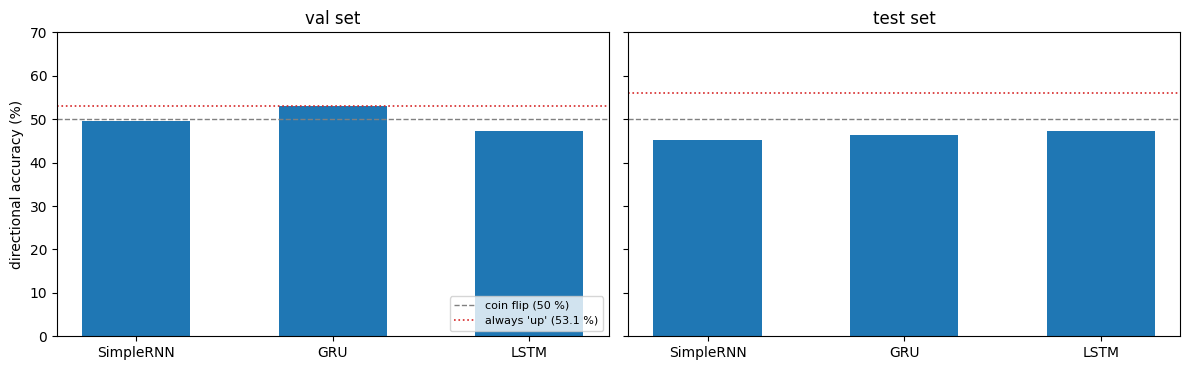

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, split in zip(axes, SPLITS):
    g = direction[direction["split"] == split]
    ax.bar(g["model"], g["DA %"], color="tab:blue", width=0.55)
    ax.axhline(50, color="grey", linestyle="--", linewidth=1, label="coin flip (50 %)")
    ax.axhline(g["majority %"].iloc[0], color="tab:red", linestyle=":", linewidth=1.2,
               label=f"always 'up' ({g['majority %'].iloc[0]:.1f} %)")
    ax.set_title(f"{split} set")
    ax.set_ylim(0, 70)
axes[0].set_ylabel("directional accuracy (%)")
axes[0].legend(loc="lower right", fontsize=8)
save("directional_accuracy.png")

## 3. The systematic downward bias
Directional accuracy below a coin flip is not evidence of "anti-skill" that could be exploited by inverting
the prediction. It is the signature of a constant offset: if the prediction sits below the last close almost
every day, the model answers "down" almost every day, and it is then wrong on every up day.

In [6]:
rows = []
for split in SPLITS:
    for kind in MODELS:
        act, prd = changes(split, preds[split][kind])
        rows.append({"split": split, "model": kind,
                     "mean predicted change": prd.mean(),
                     "median predicted change": np.median(prd),
                     "mean actual change": act.mean(),
                     "days predicted up": f"{int((prd > 0).sum())} / {len(prd)}"})
bias = pd.DataFrame(rows)
bias.round(2)

,split,model,mean predicted change,median predicted change,mean actual change,days predicted up
0,val,SimpleRNN,-0.63,-0.12,0.52,327 / 665
1,val,GRU,0.87,1.15,0.52,435 / 665
2,val,LSTM,-1.12,-0.88,0.52,274 / 665
3,test,SimpleRNN,-80.60,-39.07,2.52,23 / 665
4,test,GRU,-82.94,-38.05,2.52,32 / 665
5,test,LSTM,-63.55,-27.25,2.52,41 / 665


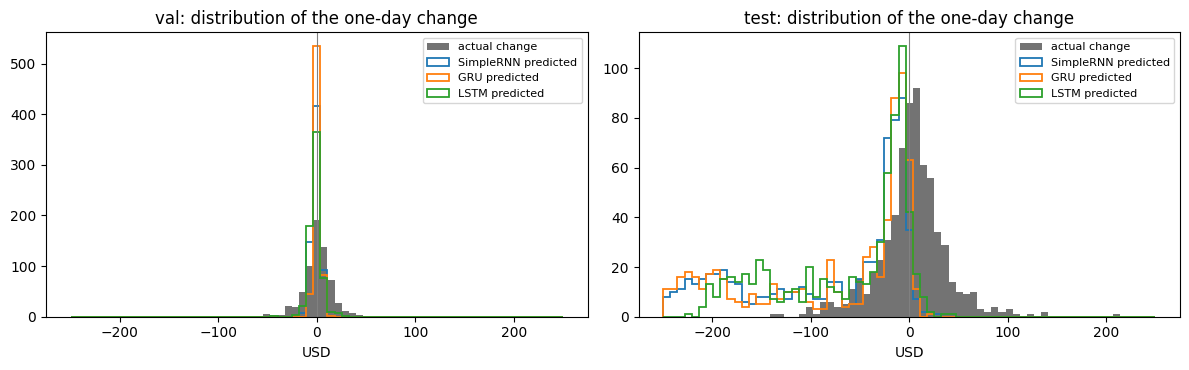

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, split in zip(axes, SPLITS):
    act, _ = changes(split, preds[split][MODELS[0]])
    bins = np.linspace(min(act.min(), -250), max(act.max(), 250), 70)
    ax.hist(act, bins=bins, alpha=0.55, label="actual change", color="black")
    for kind in MODELS:
        _, prd = changes(split, preds[split][kind])
        ax.hist(prd, bins=bins, histtype="step", linewidth=1.3, label=f"{kind} predicted")
    ax.axvline(0, color="grey", linewidth=0.8)
    ax.set_title(f"{split}: distribution of the one-day change")
    ax.set_xlabel("USD")
    ax.legend(fontsize=8)
save("change_distribution.png")

## 4. Is there any directional signal under the bias?
Two ways to ask the question, both independent of any constant offset:

1. **Debiased DA** — subtract the median predicted change before taking its sign, so only the *shape* of the
   prediction is judged.
2. **Correlation between predicted and actual change** — if the model carries any information about
   tomorrow's move, this is positive and significant. A Spearman correlation is used alongside Pearson
   because daily changes have heavy tails.

In [8]:
rows = []
for split in SPLITS:
    for kind in MODELS:
        act, prd = changes(split, preds[split][kind])
        debiased = prd - np.median(prd)
        sp = stats.spearmanr(prd, act)
        rows.append({
            "split": split, "model": kind,
            "raw DA %": 100 * (((act > 0) == (prd > 0)).mean()),
            "debiased DA %": 100 * (((act > 0) == (debiased > 0)).mean()),
            "Pearson r": np.corrcoef(prd, act)[0, 1],
            "Spearman r": sp.statistic,
            "p (Spearman)": sp.pvalue,
        })
signal = pd.DataFrame(rows)
signal.round(4)

,split,model,raw DA %,debiased DA %,Pearson r,Spearman r,p (Spearman)
0,val,SimpleRNN,49.4737,48.7218,-0.0061,-0.0163,0.6743
1,val,GRU,53.0827,50.2256,0.0377,0.0079,0.8397
2,val,LSTM,47.2180,49.0226,0.0250,-0.0178,0.6462
3,test,SimpleRNN,45.1128,51.5789,0.0381,0.0370,0.3405
4,test,GRU,46.4662,51.5789,0.0351,0.0379,0.3296
5,test,LSTM,47.2180,52.4812,0.0546,0.0519,0.1811


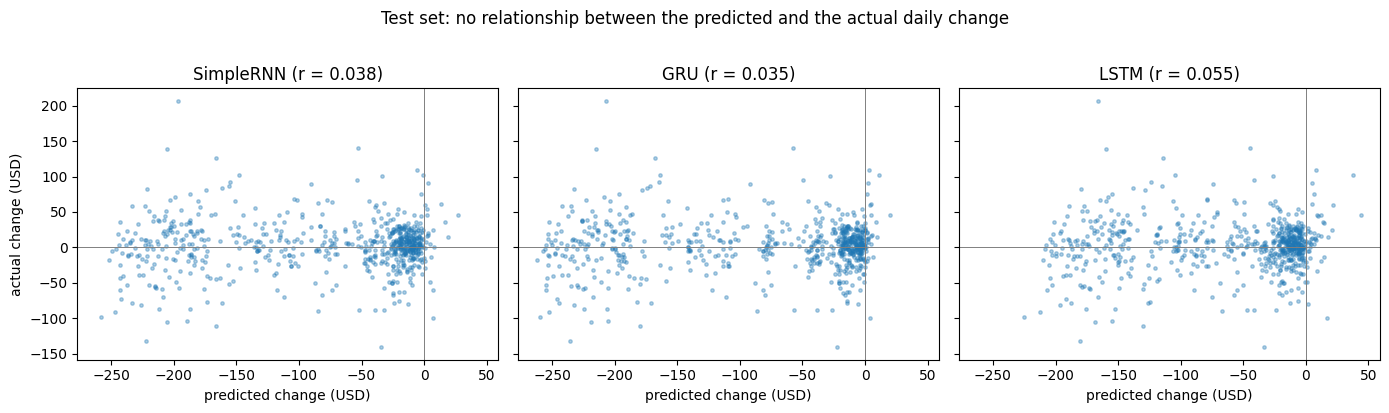

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharex=True, sharey=True)
for ax, kind in zip(axes, MODELS):
    act, prd = changes("test", preds["test"][kind])
    ax.scatter(prd, act, s=6, alpha=0.35)
    ax.axhline(0, color="grey", linewidth=0.7)
    ax.axvline(0, color="grey", linewidth=0.7)
    r = np.corrcoef(prd, act)[0, 1]
    ax.set_title(f"{kind} (r = {r:.3f})")
    ax.set_xlabel("predicted change (USD)")
axes[0].set_ylabel("actual change (USD)")
fig.suptitle("Test set: no relationship between the predicted and the actual daily change", y=1.02)
save("change_scatter.png")

## 5. MAPE and Theil's U
Two scale-free numbers that put the errors of section 7 of notebook 02 in context.

- **MAPE** — mean absolute percentage error. Unlike RMSE it is not dominated by the late test days where the
  price is highest.
- **Theil's U** — RMSE of the model divided by RMSE of the naive random-walk forecast. Above 1 means worse
  than persistence. Notebook 02 already reports this ratio in section 7; naming it connects the project to
  the standard forecasting literature.

In [10]:
rows = []
for split in SPLITS:
    X, y = data[split]
    actual = to_usd(y)
    naive = to_usd(X[:, -1, close_idx])
    rmse_naive = np.sqrt(np.mean((actual - naive) ** 2))
    rows.append({"split": split, "model": "Persistence",
                 "MAPE %": 100 * np.mean(np.abs((actual - naive) / actual)),
                 "RMSE": rmse_naive, "Theil's U": 1.0})
    for kind in MODELS:
        p = preds[split][kind]
        rows.append({"split": split, "model": kind,
                     "MAPE %": 100 * np.mean(np.abs((actual - p) / actual)),
                     "RMSE": float(np.sqrt(np.mean((actual - p) ** 2))),
                     "Theil's U": float(np.sqrt(np.mean((actual - p) ** 2)) / rmse_naive)})
scale_free = pd.DataFrame(rows)
scale_free.round(3)

,split,model,MAPE %,RMSE,Theil's U
0,val,Persistence,1.019,16.194,1.000
1,val,SimpleRNN,1.071,16.780,1.036
2,val,GRU,1.040,16.354,1.010
3,val,LSTM,1.130,17.216,1.063
4,test,Persistence,1.336,35.566,1.000
5,test,SimpleRNN,3.824,120.363,3.384
6,test,GRU,3.909,126.134,3.547
7,test,LSTM,3.163,99.193,2.789


## 6. Summary

In [11]:
summary = (direction[["split", "model", "DA %", "predicted up %"]]
           .merge(signal[["split", "model", "debiased DA %", "Spearman r", "p (Spearman)"]],
                  on=["split", "model"])
           .merge(scale_free[["split", "model", "MAPE %", "Theil's U"]], on=["split", "model"]))
summary.to_csv(os.path.join(RESULTS_DIR, "direction_metrics.csv"), index=False)
summary.round(3)

,split,model,DA %,predicted up %,debiased DA %,Spearman r,p (Spearman),MAPE %,Theil's U
0,val,SimpleRNN,49.474,49.173,48.722,-0.016,0.674,1.071,1.036
1,val,GRU,53.083,65.414,50.226,0.008,0.840,1.040,1.010
2,val,LSTM,47.218,41.203,49.023,-0.018,0.646,1.130,1.063
3,test,SimpleRNN,45.113,3.459,51.579,0.037,0.340,3.824,3.384
4,test,GRU,46.466,4.812,51.579,0.038,0.330,3.909,3.547
5,test,LSTM,47.218,6.165,52.481,0.052,0.181,3.163,2.789


## 7. Discussion

**The models have no directional skill, on either split.** On the test set directional accuracy is 45–47 %,
below a coin flip and far below the 55.9 % that "always up" would score without looking at the data. On
validation it is 47–53 %, and no result in the notebook is significantly different from chance.

**Below-chance accuracy on test is a bias, not an inverted signal.** The models predict a fall of roughly
64–83 USD *every day* while the price actually rises by 2.5 USD a day on average, so they answer "down" on
94–96 % of test days and are wrong on every up day. Inverting the predictions would not help: that would
answer "up" every day, which is the majority class and still contains no information.

**Nothing is hidden under the bias.** Once the median predicted change is removed, directional accuracy
returns to chance (48.7–52.5 %), and the correlation between the predicted and the actual daily change runs
from −0.018 to 0.055 — negative for two of the validation runs — with p-values from 0.18 to 0.84. Not one of
the twelve correlations is significant at any usual level. By this measurement the models carry no usable
information about tomorrow's move, even though section 8 of notebook 02 reports R² up to 0.97.

**This separates two problems that the required metrics conflate.** They have different causes, different
evidence and different remedies:

| Problem | Evidence | Where it shows | Can it be fixed? |
|---|---|---|---|
| Target leaves the training range | Theil's U 2.79–3.55 here, 2.9–5.8 over the 5 seeds of notebook 02; mean predicted change −64 to −83 USD | Test only | Yes — predicting the change rather than the level removes the bounded-output problem |
| The series is close to a random walk | Directional accuracy at chance; correlation ≈ 0 | **Validation and test alike** | No — this is a property of daily closing prices, not of the architecture |

The second row is the important one. On validation the bias is almost absent (mean predicted change −1.1 to
+0.9 USD against an actual +0.5) and extrapolation is mild — Theil's U there is 1.01 to 1.06, so on RMSE the
models very nearly tie the baseline — and yet there is *still* no directional skill. So the poor test RMSE
and the absence of directional skill are two different failures, and fixing the first would not produce the
second.

**What this means for the conclusions of the project.** The high R² reported in notebook 02 comes entirely
from tracking the level of a trending series. Requirement §7 asks for MAE, MSE, RMSE and R², and those are
reported there in full; the measurements here are an addition for §8.6, not a replacement. They are what
justifies the claim that a high R² on a price level is not evidence of a learned temporal pattern.